# Module 1 · Notebook 2: Autograd on NumPy arrays

Notebook 1 built autograd on single numbers. The calculus does not change here. What changes is **shapes**: every gradient must have exactly the shape of the thing it belongs to.

| Step | What we do |
|---|---|
| 1 | Why scalars cannot scale (timing) |
| 2 | The matmul gradient, derived from shapes |
| 3 | Broadcasting: gradients must be *summed back* |
| 4 | A `Tensor` class + `backward()` |
| 5 | Gradient check for every op (with a random-projection trick) |
| 6 | Softmax + cross-entropy from primitives, and the overflow trap |
| 7 | End to end: gradcheck a tiny MLP, then train it |

In [12]:
import sys, time
import numpy as np
import matplotlib.pyplot as plt

print("python", sys.version.split()[0], "| numpy", np.__version__)

python 3.12.15 | numpy 2.5.3


## Step 1: Why scalars cannot scale

A tiny transformer layer does matrix multiplies like `(64, 64) @ (64, 64)`: that is $64^3 \approx 262{,}000$ multiply-adds. With one Python object per number (notebook 1's `Value`), each of those is a Python call plus a closure.

Below: the same matmul as a pure-Python triple loop vs. NumPy. (A `Value` version would be slower still, since every multiply also allocates an object.)

In [13]:
n = 64
A = np.random.default_rng(0).standard_normal((n, n))
B = np.random.default_rng(1).standard_normal((n, n))
A_list, B_list = A.tolist(), B.tolist()

t0 = time.perf_counter()
C_py = [[sum(A_list[i][k] * B_list[k][j] for k in range(n)) for j in range(n)] for i in range(n)]
t_py = time.perf_counter() - t0

t0 = time.perf_counter()
for _ in range(100):
    C_np = A @ B
t_np = (time.perf_counter() - t0) / 100

print(f"pure Python: {t_py * 1e3:8.2f} ms")
print(f"NumPy      : {t_np * 1e3:8.4f} ms")
print(f"speedup    : ~{t_py / t_np:,.0f}x   | same result: {np.allclose(C_py, C_np)}")

pure Python:    28.18 ms
NumPy      :   0.0191 ms
speedup    : ~1,479x   | same result: True


So we move from "one object per number" to "one object per **array**". The graph gets *much* smaller: a whole layer is a handful of nodes instead of hundreds of thousands.

## Step 2: The matmul gradient, derived from shapes

Let $Y = XW$ with $X$: `(N, D)`, $W$: `(D, M)`, $Y$: `(N, M)`. Backward gives us $G = \frac{\partial L}{\partial Y}$, shape `(N, M)`.

We need $\frac{\partial L}{\partial X}$ with shape `(N, D)` and $\frac{\partial L}{\partial W}$ with shape `(D, M)`. Each element $Y_{ij} = \sum_k X_{ik} W_{kj}$, so $X_{ik}$ affects row $i$ of $Y$ through $W_{kj}$, and $W_{kj}$ affects column $j$ through $X_{ik}$. Summing those paths gives:

$$\frac{\partial L}{\partial X} = G\,W^\top \;\; \underbrace{(N,M)(M,D)}_{=(N,D)\ \checkmark} \qquad\qquad \frac{\partial L}{\partial W} = X^\top G \;\; \underbrace{(D,N)(N,M)}_{=(D,M)\ \checkmark}$$

A useful habit: **if you forget the formula, the shapes only fit one way.**

In [14]:
rng = np.random.default_rng(0)
X = rng.standard_normal((5, 3))
W = rng.standard_normal((3, 4))
R = rng.standard_normal((5, 4))       # L = sum(R * (X @ W))  =>  dL/dY = R

def L_of(W_):
    return np.sum(R * (X @ W_))

G = R
dW = X.T @ G                          # the formula
dX = G @ W.T
print("dW shape:", dW.shape, "| dX shape:", dX.shape)

# finite-difference check on one element of W
h = 1e-6
Wp, Wm = W.copy(), W.copy()
Wp[1, 2] += h; Wm[1, 2] -= h
print(f"dW[1,2]  formula={dW[1, 2]:+.8f}   numerical={(L_of(Wp) - L_of(Wm)) / (2 * h):+.8f}")

dW shape: (3, 4) | dX shape: (5, 3)
dW[1,2]  formula=-1.31646420   numerical=-1.31646420


## Step 3: Broadcasting, and why gradients must be summed back

When we write `X @ W + b` with $b$ of shape `(4,)`, NumPy silently **copies** $b$ to every one of the $N$ rows. So $b$ is "used $N$ times", and from notebook 1 we know: a value used many times gets the **sum** of all its gradients.

The rule, `unbroadcast(grad, shape)`:
1. Sum away the leading dimensions that broadcasting added.
2. Sum (keeping the dim) over any axis where the original size was 1.

In [15]:
def unbroadcast(grad, shape):
    # Sum grad down to `shape`, undoing NumPy broadcasting.
    while grad.ndim > len(shape):                  # 1) leading dims added by broadcasting
        grad = grad.sum(axis=0)
    for i, n in enumerate(shape):                  # 2) dims that were size 1
        if n == 1 and grad.shape[i] != 1:
            grad = grad.sum(axis=i, keepdims=True)
    return grad

g = np.ones((32, 4))
print("bias (4,)     <- grad", g.shape, "->", unbroadcast(g, (4,)).shape, "values:", unbroadcast(g, (4,)))
print("col  (32, 1)  <- grad", g.shape, "->", unbroadcast(g, (32, 1)).shape)
print("scalar ()     <- grad", g.shape, "->", unbroadcast(g, ()).shape, "value:", unbroadcast(g, ()))

bias (4,)     <- grad (32, 4) -> (4,) values: [32. 32. 32. 32.]
col  (32, 1)  <- grad (32, 4) -> (32, 1)
scalar ()     <- grad (32, 4) -> () value: 128.0


Each bias entry gets gradient **32**: one contribution per row of the batch. Forgetting this is a classic bug: the shapes "almost" work, and NumPy may even broadcast the wrong-shaped gradient back without complaint.

## Step 4: The `Tensor` class

Same design as `Value`, with three changes:
- `data` and `grad` are NumPy arrays of the same shape.
- Every op that can broadcast calls `unbroadcast` in its backward.
- New ops that only exist for arrays: `matmul`, `sum`, `mean`, `reshape`, `transpose`.

`matmul` is written for **batched** inputs (`(..., N, D) @ (..., D, M)`), because attention in Module 3 needs `(batch, heads, T, d)` shapes.

**One difference from `autograd.py`:** `backward()` below builds the topological order with recursion, because it is easier to read. Python stops recursion at about 1,000 levels, so this version crashes on graphs deeper than ~1,000 ops; `autograd.py` uses an explicit stack instead, and its tests run a 5,000-op chain.

In [16]:
class Tensor:
    # A NumPy array that remembers how it was computed.

    __array_ufunc__ = None   # make `ndarray + Tensor` call Tensor.__radd__ instead of NumPy

    def __init__(self, data, _children=(), _op=""):
        self.data = np.asarray(data, dtype=np.float64)
        self.grad = np.zeros_like(self.data)
        self._prev = set(_children)
        self._op = _op
        self._backward = lambda: None

    @property
    def shape(self):
        return self.data.shape

    def __repr__(self):
        return f"Tensor(shape={self.shape}, op='{self._op}')"

    # ---- elementwise ops (with broadcasting) ----

    def __add__(self, other):
        other = other if isinstance(other, Tensor) else Tensor(other)
        out = Tensor(self.data + other.data, (self, other), "+")
        def _backward():
            self.grad  += unbroadcast(out.grad, self.shape)
            other.grad += unbroadcast(out.grad, other.shape)
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Tensor) else Tensor(other)
        out = Tensor(self.data * other.data, (self, other), "*")
        def _backward():
            self.grad  += unbroadcast(other.data * out.grad, self.shape)
            other.grad += unbroadcast(self.data  * out.grad, other.shape)
        out._backward = _backward
        return out

    def __pow__(self, n):
        assert isinstance(n, (int, float)), "only constant exponents"
        out = Tensor(self.data ** n, (self,), f"**{n}")
        def _backward():
            self.grad += n * self.data ** (n - 1) * out.grad
        out._backward = _backward
        return out

    def exp(self):
        out = Tensor(np.exp(self.data), (self,), "exp")
        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out

    def log(self):
        out = Tensor(np.log(self.data), (self,), "log")
        def _backward():
            self.grad += out.grad / self.data
        out._backward = _backward
        return out

    def tanh(self):
        t = np.tanh(self.data)
        out = Tensor(t, (self,), "tanh")
        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def relu(self):
        out = Tensor(np.maximum(self.data, 0), (self,), "relu")
        def _backward():
            self.grad += (self.data > 0) * out.grad
        out._backward = _backward
        return out

    # ---- matrix and shape ops ----

    def __matmul__(self, other):
        other = other if isinstance(other, Tensor) else Tensor(other)
        assert self.data.ndim >= 2 and other.data.ndim >= 2, "matmul needs >= 2-D inputs"
        out = Tensor(self.data @ other.data, (self, other), "@")
        def _backward():
            self.grad  += unbroadcast(out.grad @ np.swapaxes(other.data, -1, -2), self.shape)  # G W^T
            other.grad += unbroadcast(np.swapaxes(self.data, -1, -2) @ out.grad, other.shape)  # X^T G
        out._backward = _backward
        return out

    def sum(self, axis=None, keepdims=False):
        out = Tensor(self.data.sum(axis=axis, keepdims=keepdims), (self,), "sum")
        def _backward():
            g = out.grad
            if axis is not None and not keepdims:
                g = np.expand_dims(g, axis)              # put the summed axis back as size 1
            self.grad += np.broadcast_to(g, self.shape)  # every input element gets the same grad
        out._backward = _backward
        return out

    def reshape(self, *shape):
        out = Tensor(self.data.reshape(*shape), (self,), "reshape")
        def _backward():
            self.grad += out.grad.reshape(self.shape)
        out._backward = _backward
        return out

    def transpose(self, axes=None):
        out = Tensor(self.data.transpose(axes), (self,), "transpose")
        inv = None if axes is None else np.argsort(axes)   # the permutation that undoes `axes`
        def _backward():
            self.grad += out.grad.transpose(inv)
        out._backward = _backward
        return out

    # ---- derived ops: no new derivative code ----

    def mean(self, axis=None, keepdims=False):
        s = self.sum(axis=axis, keepdims=keepdims)
        return s * (s.data.size / self.data.size)

    def __neg__(self):              return self * -1
    def __sub__(self, other):       return self + (-other)
    def __truediv__(self, other):   return self * other**-1
    def __radd__(self, other):      return self + other
    def __rmul__(self, other):      return self * other
    def __rsub__(self, other):      return other + (-self)
    def __rtruediv__(self, other):  return other * self**-1

    # ---- backward: identical idea to notebook 1 ----

    def backward(self):
        order, visited = [], set()
        def build(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build(child)
                order.append(v)
        build(self)
        self.grad = np.ones_like(self.data)   # dL/dL = 1 (for a non-scalar output: grad of its sum)
        for v in reversed(order):
            v._backward()


# a linear layer: one graph node per array, not per number
X = Tensor(np.random.default_rng(0).standard_normal((32, 3)))
W = Tensor(np.random.default_rng(1).standard_normal((3, 4)))
b = Tensor(np.zeros(4))
L = (X @ W + b).tanh().sum()
L.backward()
print("L:", L.data, "| W.grad shape:", W.grad.shape, "| b.grad shape:", b.grad.shape)

L: 6.25842200311426 | W.grad shape: (3, 4) | b.grad shape: (4,)


## Step 5: Gradient check for every op

Same referee as notebook 1, now per array element. Two upgrades:

**1. Reduce to a scalar with random weights.** If an op outputs an array, we check $L = \sum (R \odot \text{out})$ with a fixed random $R$, *not* a plain `sum()`. With a plain sum, every output element gets gradient 1, and some bugs become invisible: for example, a transpose that forgets to transpose its gradient back still passes on a square matrix. Random $R$ gives every output element a different weight, so such bugs show up.

**2. Compare whole gradient arrays with a norm:**
$$\text{rel\_err} = \frac{\lVert g_{\text{auto}} - g_{\text{num}} \rVert}{\lVert g_{\text{auto}} \rVert + \lVert g_{\text{num}} \rVert}$$
Per-element relative error blows up on elements whose true gradient is ~0; the norm version does not.

In [17]:
def gradcheck(fn, inputs, h=1e-6, seed=0):
    # fn: list of Tensors -> Tensor. inputs: list of float64 arrays. Returns worst rel_err.
    out_shape = fn([Tensor(x) for x in inputs]).shape
    R = np.random.default_rng(seed).standard_normal(out_shape)
    loss = lambda ts: (fn(ts) * R).sum()

    ts = [Tensor(x) for x in inputs]
    loss(ts).backward()

    worst = 0.0
    for i, x in enumerate(inputs):
        num = np.zeros_like(x)
        for idx in np.ndindex(x.shape):
            xp, xm = x.copy(), x.copy()
            xp[idx] += h; xm[idx] -= h
            args_p = [Tensor(xp if j == i else inputs[j]) for j in range(len(inputs))]
            args_m = [Tensor(xm if j == i else inputs[j]) for j in range(len(inputs))]
            num[idx] = (loss(args_p).data - loss(args_m).data) / (2 * h)
        ana = ts[i].grad
        err = np.linalg.norm(ana - num) / max(np.linalg.norm(ana) + np.linalg.norm(num), 1e-12)
        worst = max(worst, err)
    return worst

rng = np.random.default_rng(42)
def rand(*shape, positive=False):
    x = rng.standard_normal(shape)
    return np.abs(x) + 0.5 if positive else x

tests = [
    ("add (3,4)+(3,4)",          lambda t: t[0] + t[1],                 [rand(3, 4), rand(3, 4)]),
    ("add bias (3,4)+(4,)",      lambda t: t[0] + t[1],                 [rand(3, 4), rand(4)]),
    ("add (3,1)+(1,4)",          lambda t: t[0] + t[1],                 [rand(3, 1), rand(1, 4)]),
    ("mul (3,4)*(3,1)",          lambda t: t[0] * t[1],                 [rand(3, 4), rand(3, 1)]),
    ("div",                      lambda t: t[0] / t[1],                 [rand(3, 4), rand(3, 4, positive=True)]),
    ("pow 3",                    lambda t: t[0] ** 3,                   [rand(3, 4)]),
    ("exp",                      lambda t: t[0].exp(),                  [rand(3, 4)]),
    ("log",                      lambda t: t[0].log(),                  [rand(3, 4, positive=True)]),
    ("tanh",                     lambda t: t[0].tanh(),                 [rand(3, 4)]),
    ("relu",                     lambda t: t[0].relu(),                 [rand(3, 4)]),
    ("matmul (3,4)@(4,5)",       lambda t: t[0] @ t[1],                 [rand(3, 4), rand(4, 5)]),
    ("batched (2,3,4)@(4,5)",    lambda t: t[0] @ t[1],                 [rand(2, 3, 4), rand(4, 5)]),
    ("batched (2,3,4)@(2,4,5)",  lambda t: t[0] @ t[1],                 [rand(2, 3, 4), rand(2, 4, 5)]),
    ("sum all",                  lambda t: t[0].sum(),                  [rand(3, 4)]),
    ("sum axis=0",               lambda t: t[0].sum(axis=0),            [rand(3, 4)]),
    ("sum axis=1 keepdims",      lambda t: t[0].sum(axis=1, keepdims=True), [rand(3, 4)]),
    ("mean axis=-1",             lambda t: t[0].mean(axis=-1),          [rand(3, 4)]),
    ("reshape (3,4)->(4,3)",     lambda t: t[0].reshape(4, 3),          [rand(3, 4)]),
    ("transpose (2,3,4)->(4,2,3)", lambda t: t[0].transpose((2, 0, 1)), [rand(2, 3, 4)]),
    ("layer tanh(XW+b)",         lambda t: (t[0] @ t[1] + t[2]).tanh(), [rand(5, 3), rand(3, 4), rand(4)]),
]

for name, fn, inputs in tests:
    err = gradcheck(fn, inputs)
    print(f"{name:28s} rel_err = {err:.2e}   {'OK' if err < 1e-6 else 'FAIL'}")

add (3,4)+(3,4)              rel_err = 1.21e-10   OK
add bias (3,4)+(4,)          rel_err = 1.22e-10   OK
add (3,1)+(1,4)              rel_err = 9.92e-11   OK
mul (3,4)*(3,1)              rel_err = 1.39e-10   OK
div                          rel_err = 2.58e-10   OK
pow 3                        rel_err = 5.61e-11   OK
exp                          rel_err = 5.59e-11   OK
log                          rel_err = 3.05e-11   OK
tanh                         rel_err = 1.06e-10   OK
relu                         rel_err = 3.26e-11   OK
matmul (3,4)@(4,5)           rel_err = 1.63e-10   OK
batched (2,3,4)@(4,5)        rel_err = 1.60e-10   OK
batched (2,3,4)@(2,4,5)      rel_err = 4.88e-10   OK
sum all                      rel_err = 3.58e-11   OK
sum axis=0                   rel_err = 9.18e-11   OK
sum axis=1 keepdims          rel_err = 3.62e-11   OK
mean axis=-1                 rel_err = 8.09e-11   OK
reshape (3,4)->(4,3)         rel_err = 1.90e-10   OK
transpose (2,3,4)->(4,2,3)   rel_err = 1.34e-1

## Step 6: Softmax and cross-entropy, built from primitives

We do **not** add softmax as a new op with its own derivative. We build it from `exp`, `sum`, `/`, `log`, and the gradient comes out of the engine for free.

**The trap:** float64 can hold numbers up to about $1.8 \times 10^{308} \approx e^{709}$. So $e^{1000}$ overflows to `inf`, and the naive softmax then computes $\frac{\infty}{\infty}$, which is undefined; IEEE-754 floating point returns `nan` (not a number). The cell below shows this bug **on purpose**. In a real training run it shows up as `loss = nan`, and from that step on every gradient is `nan` too.

**The fix:** subtract the row max first. This is *exact*, not an approximation, because softmax ignores constant shifts:
$$\text{softmax}(x - c)_i = \frac{e^{x_i - c}}{\sum_j e^{x_j - c}} = \frac{e^{-c}\,e^{x_i}}{e^{-c}\sum_j e^{x_j}} = \text{softmax}(x)_i$$
Because the output does not depend on $c$, we can treat the max as a **plain constant** (no gradient through it), and the gradient is still exactly right.

In [18]:
def softmax(x, axis=-1):
    shifted = x - x.data.max(axis=axis, keepdims=True)   # constant shift: no gradient needed
    e = shifted.exp()
    return e / e.sum(axis=axis, keepdims=True)

def cross_entropy(logits, targets):
    # logits: Tensor (N, C). targets: int array (N,). Returns mean negative log-likelihood.
    shifted = logits - logits.data.max(axis=-1, keepdims=True)
    log_probs = shifted - shifted.exp().sum(axis=-1, keepdims=True).log()   # log-softmax
    onehot = np.eye(logits.shape[-1])[targets]
    return -(log_probs * onehot).sum() / len(targets)

with np.errstate(over="ignore"):
    print("exp(709)      :", np.exp(709.0))
    print("exp(710)      :", np.exp(710.0), "  <- past the float64 limit")

big = np.array([[1000.0, 1001.0, 1002.0]])

# naive softmax: shows the bug on purpose
with np.errstate(over="ignore", invalid="ignore"):
    e = np.exp(big)
    naive = e / e.sum()
print("\nnaive : exp(logits) =", e, "| sum =", e.sum())
print("naive : softmax     =", naive, "  <- inf / inf = nan")

# stable softmax: subtract the row max first -> exp([-2, -1, 0]), all safe
stable = softmax(Tensor(big)).data
print("\nstable: shifted     =", big - big.max())
print("stable: softmax     =", stable, "| sum =", stable.sum())

exp(709)      : 8.218407461554972e+307
exp(710)      : inf   <- past the float64 limit

naive : exp(logits) = [[inf inf inf]] | sum = inf
naive : softmax     = [[nan nan nan]]   <- inf / inf = nan

stable: shifted     = [[-2. -1.  0.]]
stable: softmax     = [[0.09003057 0.24472847 0.66524096]] | sum = 0.9999999999999998


**Two proofs for cross-entropy:**
1. The gradient check, as usual.
2. A known **closed form**: for mean cross-entropy over softmax, $\frac{\partial L}{\partial \text{logits}} = \frac{\text{softmax}(\text{logits}) - \text{onehot}}{N}$. Our engine never saw this formula; it should still produce it exactly.

In [19]:
logits_np = rand(6, 5)
targets = np.array([0, 3, 1, 4, 2, 3])

print(f"softmax gradcheck      : {gradcheck(lambda t: softmax(t[0]), [logits_np]):.2e}")
print(f"cross-entropy gradcheck: {gradcheck(lambda t: cross_entropy(t[0], targets), [logits_np]):.2e}")

logits = Tensor(logits_np)
cross_entropy(logits, targets).backward()
closed_form = (softmax(Tensor(logits_np)).data - np.eye(5)[targets]) / len(targets)
print(f"max |autograd - closed form| = {np.abs(logits.grad - closed_form).max():.2e}")

softmax gradcheck      : 1.88e-10
cross-entropy gradcheck: 1.13e-09
max |autograd - closed form| = 2.78e-17


## Step 7: End to end, a tiny MLP

**7a. Gradcheck the whole network.** Two layers, tanh, cross-entropy, against all four parameter arrays at once. If this passes, every op in the chain is wired correctly together, not just in isolation.

In [20]:
X_small = rand(8, 2)
y_small = np.array([0, 1, 2, 0, 1, 2, 0, 1])

def mlp_loss(t):
    W1, b1, W2, b2 = t
    h = (Tensor(X_small) @ W1 + b1).tanh()
    return cross_entropy(h @ W2 + b2, y_small)

params0 = [rand(2, 16) * 0.5, np.zeros(16), rand(16, 3) * 0.5, np.zeros(3)]
print(f"MLP end-to-end gradcheck: {gradcheck(mlp_loss, params0):.2e}")

MLP end-to-end gradcheck: 5.33e-10


**7b. Train it.** A classic toy problem: 3 interleaved spirals that no straight line can separate. Plain gradient descent, full batch, with the loop written by hand.

Note the `zero_grad` line: notebook 1, Step 6a showed what happens without it.

**Learning rate:** `lr = 0.5`. With `lr = 1.0` the same run reaches the same 99.3% accuracy, but the loss jumps back up 14 times (spikes around steps 100–250), because some steps overshoot. Module 5 studies loss spikes and fixes them with warmup and gradient clipping; here we just pick a stable rate.

In [21]:
def make_spiral(n_per_class=100, n_classes=3, seed=0):
    r_ = np.random.default_rng(seed)
    X, y = [], []
    for k in range(n_classes):
        r = np.linspace(0.0, 1.0, n_per_class)
        t = np.linspace(k * 4, (k + 1) * 4, n_per_class) + r_.standard_normal(n_per_class) * 0.2
        X.append(np.c_[r * np.sin(t), r * np.cos(t)])
        y.append(np.full(n_per_class, k))
    return np.concatenate(X), np.concatenate(y)

Xs, ys = make_spiral()
init = np.random.default_rng(0)
H = 64
W1 = Tensor(init.standard_normal((2, H)) * 1.0)
b1 = Tensor(np.zeros(H))
W2 = Tensor(init.standard_normal((H, 3)) * (1 / np.sqrt(H)))
b2 = Tensor(np.zeros(3))
params = [W1, b1, W2, b2]

def forward(X):
    return (Tensor(X) @ W1 + b1).tanh() @ W2 + b2

lr, steps, losses = 0.5, 3000, []
t0 = time.perf_counter()
for step in range(steps):
    for p in params:
        p.grad = np.zeros_like(p.data)        # zero_grad
    loss = cross_entropy(forward(Xs), ys)
    loss.backward()
    for p in params:
        p.data -= lr * p.grad                 # gradient descent step
    losses.append(loss.data.item())
elapsed = time.perf_counter() - t0

X_test, y_test = make_spiral(seed=1)          # same spirals, new noise: points the model never saw
acc      = (forward(Xs).data.argmax(axis=1) == ys).mean()
test_acc = (forward(X_test).data.argmax(axis=1) == y_test).mean()
test_loss = cross_entropy(forward(X_test), y_test).data.item()
print(f"{steps} steps in {elapsed:.1f}s")
print(f"train: loss {losses[-1]:.3f}  accuracy {acc:.1%}")
print(f"test : loss {test_loss:.3f}  accuracy {test_acc:.1%}")

3000 steps in 2.9s
train: loss 0.039  accuracy 99.3%
test : loss 0.046  accuracy 99.0%


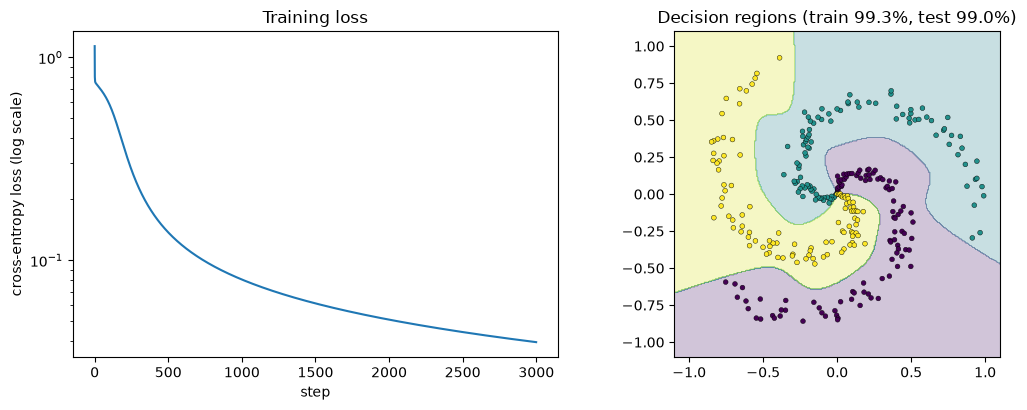

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

ax1.plot(losses)
ax1.set_yscale("log")
ax1.set_xlabel("step"); ax1.set_ylabel("cross-entropy loss (log scale)")
ax1.set_title("Training loss")

xx, yy = np.meshgrid(np.linspace(-1.1, 1.1, 300), np.linspace(-1.1, 1.1, 300))
grid_pred = forward(np.c_[xx.ravel(), yy.ravel()]).data.argmax(axis=1).reshape(xx.shape)
ax2.contourf(xx, yy, grid_pred, alpha=0.25, cmap="viridis")
ax2.scatter(Xs[:, 0], Xs[:, 1], c=ys, s=12, cmap="viridis", edgecolors="k", linewidths=0.3)
ax2.set_title(f"Decision regions (train {acc:.1%}, test {test_acc:.1%})")
ax2.set_aspect("equal")

plt.tight_layout()
plt.show()

### Is it overfitting?

A fair question, since 99% *train* accuracy alone proves nothing about generalization. That is why we also scored a **held-out set**: the same three spirals drawn with different noise, never used for training.

- **Train vs test accuracy: 99.3% vs 99.0%.** The model learned the spiral shape, not the individual points. The smooth decision regions agree: an overfit model would carve jagged islands around single points.
- **The early warning sign is in the loss, not the accuracy.** Trained for 20,000 steps instead of 3,000, train loss falls 0.039 → 0.016 but test loss only falls 0.046 → 0.031, so the gap between them doubles (0.007 → 0.015): the model grows over-confident on its own points while its predictions stay the same.
- **Why so mild:** 387 parameters for 300 points is a small model, and the test set comes from the same simple generator. Real data would show a bigger gap.

Step 7's job is to show the engine can **optimize**. Measuring **generalization** properly (train/val/test splits, confidence intervals) is Module 5 and Module 14.

## Summary

- **Same engine as notebook 1**: local derivatives, chain rule, topological order. Only the bookkeeping changed.
- **Shapes are the new source of bugs.** matmul: $G W^\top$ and $X^\top G$. Broadcasting: sum the gradient back.
- **Gradcheck upgrades**: random-weighted output (so symmetric bugs can't hide), norm-based relative error.
- **Softmax/CE built from primitives** match the textbook closed form, with no hand-written derivative.
- **It trains**: a hand-written loop learns a non-linear boundary, and it holds up on held-out data (99.3% train, 99.0% test).

## Next: Notebook 3, the experiment

"How small should $h$ be in a gradient check?" Sweep $h$ from $10^{-1}$ to $10^{-12}$, in float64 and float32, and plot the error. Expected: a **U-shaped curve** (too big: the approximation is wrong; too small: floating-point rounding takes over).